In [8]:
from sklearn.datasets import fetch_california_housing

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [18]:
df=fetch_california_housing()

In [19]:
df.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'feature_names', 'DESCR'])

In [20]:
df.feature_names

['MedInc',
 'HouseAge',
 'AveRooms',
 'AveBedrms',
 'Population',
 'AveOccup',
 'Latitude',
 'Longitude']

In [21]:
dataset=pd.DataFrame(df.data,columns=df.feature_names)

In [22]:
dataset.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [23]:
dataset['price']=df.target

In [24]:
dataset.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


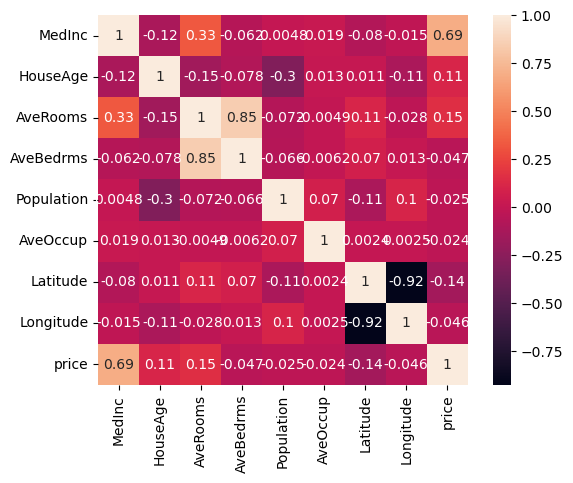

In [28]:
sns.heatmap(dataset.corr(),annot=True,square=True)
plt.show()

In [42]:
# divide data in independent and dependent features

# X=dataset[['AveBedrms','MedInc','HouseAge','AveRooms','Population','AveOccup','Latitude','Longitude']]
# y=dataset['price']

X=dataset.iloc[ : , :-1]
y=dataset.iloc[ : , -1]

In [48]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=42,test_size=0.33)

In [49]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()

X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [50]:
from sklearn.linear_model import LinearRegression

model=LinearRegression()

model.fit(X_train,y_train)

LinearRegression()

In [51]:
y_pred=model.predict(X_test)

In [52]:
from sklearn.metrics import r2_score

score=r2_score(y_pred,y_test)
score

0.3395742960386734

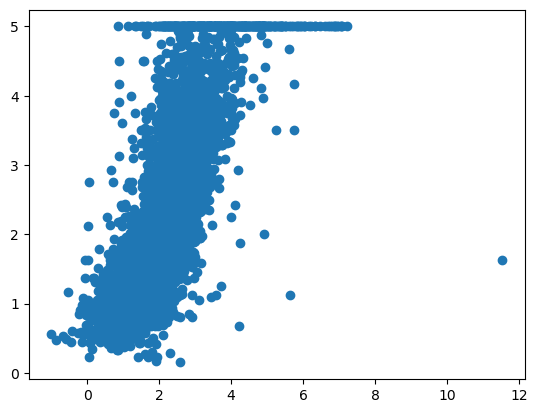

In [ ]:
#Assumption

plt.scatter(y_pred,y_test) #should be in linear relationship
plt.show()

In [54]:
residuals=y_pred-y_test

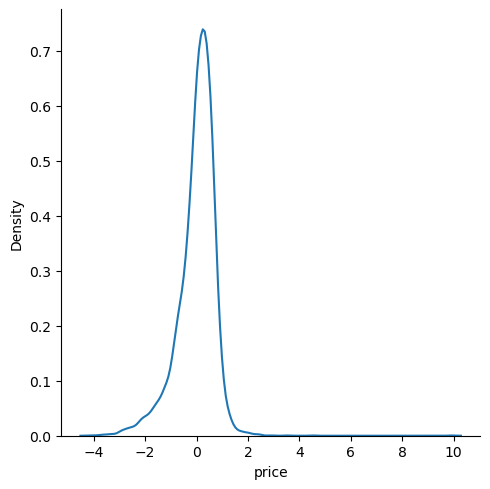

In [ ]:
sns.displot(residuals,kind='kde')  # if it is uniformly distributed then the model is performing well
plt.show()

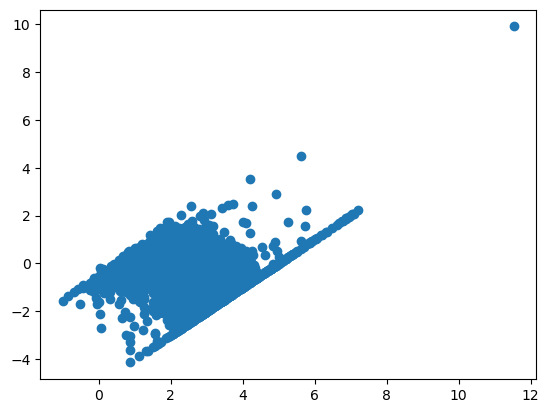

In [ ]:
plt.scatter(y_pred,residuals) # we should get a uniformly distributed graph
plt.show()

In [59]:
import pickle

pickle.dump(model,open('model.pkl','wb'))

In [62]:
pickle.load(open('model.pkl','rb'))

LinearRegression()